# Smog Album: Cities Whose Air Swings the Most

Issue #49. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md).

**What this notebook decides:** the album's cities, and the data each city's track plays. Seoul is always in (user, 2026-11-15). The others are the cities whose PM2.5 swings between its lows and its highs **most often** during one year, at most one city per region, so the album travels the world.

**How a swing is counted (user, 2026-11-15):** not how high the air gets, but how often it goes back and forth. For each city we take its own year of daily PM2.5, mark its low band (the cleanest 10 % of days) and its high band (the dirtiest 10 %), and count every time the air crosses from one band to the other. A day in between changes nothing; only a full crossing counts.

**How much data:** a track plays one year in about 40 seconds, so a day lasts about a tenth of a second. One value per city per day is all the music can carry; hourly values would pass 24 to a beat and go unheard. The notebook takes one hour a day (00:30 UTC) from a 1° world grid and keeps only the candidate cities' values.

**Steps:**

1. EIC's message about PM2.5 (5151).
2. One value a day for every candidate city in 2025.
3. The swings of every city, ranked; Seoul plus one city per region.
4. Each picked city's year in a box around it, exported as its track.

> Picking cities by how often their air swings is **ours**. EIC 5151 shows the whole world's PM2.5 and names no city.

Run with `npm run notebook`. The first run reads one 1° world grid per day of 2025 from NASA's OPeNDAP server (about 70 MB, 2–3 minutes) and keeps only the cities' values in `data/smog/raw/screen/` (under 1 MB), plus one day's grid for the map. It then reads a 33 × 33 cell box around each picked city per day (about 7 MB in all) into `data/smog/raw/box/` and exports the tracks to `data/smog/tracks/`.

In [1]:
import html
import json
import re
import struct
import time
from concurrent.futures import ThreadPoolExecutor
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/smog/raw")
for sub in ("api", "natural_earth", "screen"):
    (RAW / sub).mkdir(parents=True, exist_ok=True)

YEAR = 2025
DAYS = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31", freq="D").date

# GEOS-CF v1, the hourly surface air quality collection, served by OPeNDAP so a box or one cell can be read alone.
OPENDAP = "https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1"
VARIABLE = "pm25_rh35_gcc"                 # PM2.5 at 35 % relative humidity, µg/m³
FIRST_HOUR = datetime(2018, 1, 1, 0, 30, tzinfo=timezone.utc)  # hourly means, stamped mid-hour
GRID_DEG = 0.25
LON_POINTS = 1440

SCREEN_STRIDE = 4                          # every 4th cell: a 1° grid
SAMPLE_UTC = 0                             # one hour a day: the mean of 00:00-01:00 UTC
LOW_Q, HIGH_Q = 0.10, 0.90                 # a city's low and high bands, from its own year
MUST = "Seoul"                             # always in the album (user)
PICKS = 3                                  # cities besides Seoul, each from a different region
PARALLEL = 6
RETRIES = 4
TIMEOUT_SEC = 120

NATURAL_EARTH = "https://naciscdn.org/naturalearth/110m/cultural"
NATURAL_EARTH_50M = "https://naciscdn.org/naturalearth/50m/cultural"
CREDIT = f"Source: GEOS-CF v1 (NASA GMAO), surface PM2.5 ({VARIABLE}), {YEAR}"


def download(name, url):
    path = RAW / name
    if not path.exists():
        r = requests.get(url, timeout=TIMEOUT_SEC)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path


def svs_page(page_id):
    path = RAW / "api" / f"{page_id}.json"
    if not path.exists():
        path.write_text(requests.get(f"https://svs.gsfc.nasa.gov/api/{page_id}", timeout=60).text)
    return json.loads(path.read_text())


def plain(text):
    return re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", text or ""))).strip()


def source_note(ax, text=CREDIT, y=-38):
    ax.annotate(text, (0, 0), (0, y), xycoords="axes fraction", textcoords="offset points", fontsize=8, color="gray")

## 1. Links

### 1.1 EIC page and what it cites

Built from the SVS API.

In [2]:
PAGES = [5151]


def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets", []):
        name = d["name"] or "unnamed dataset"
        out.append(f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link")
    return "<br>".join(out) or "none"


rows = ["| SVS page | SVS API | Cited source |", "| --- | --- | --- |"]
for i in PAGES:
    rows.append(f"| [{i} {svs_page(i)['title']}](https://svs.gsfc.nasa.gov/{i}/) | "
                f"[api/{i}](https://svs.gsfc.nasa.gov/api/{i}) | {cited(i)} |")
display(Markdown("\n".join(rows)))

| SVS page | SVS API | Cited source |
| --- | --- | --- |
| [5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) | [api/5151](https://svs.gsfc.nasa.gov/api/5151) | [GEOS-CF](https://portal.nccs.nasa.gov/datashare/gmao/geos-cf/v2/) |

Gallery path: EIC Dashboards → [Air Quality Dashboard](https://svs.gsfc.nasa.gov/gallery/air-quality-dashboard/) → Models: Air Quality → 5151 (also under the Earth Now Dashboard and Daily Visualizations).

### 1.2 What this notebook downloads

| Downloaded file | Dataset page | Note |
| --- | --- | --- |
| `https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1.dods?pm25_rh35_gcc[<hour>][0][<lat>][<lon>]`: per day of 2025, a 1° world grid at 00:30 UTC | [GEOS-CF (NASA GMAO)](https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/) | Same dataset as cited, older version, public. 5151 links GEOS-CF **v2**, which starts on 2025-08-04, so it holds no whole calendar year. v1 runs 2018-01-01 to 2026-01-02 and holds all of 2025 (user, 2026-11-15). |
| [ne_110m_populated_places.zip](https://naciscdn.org/naturalearth/110m/cultural/ne_110m_populated_places.zip) | [Natural Earth](https://www.naturalearthdata.com/downloads/110m-cultural-vectors/) | Not from EIC, public domain. The candidate cities: 243 capitals and major cities. |
| [ne_50m_admin_0_countries.zip](https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip) | [Natural Earth](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/) | Not from EIC, public domain. Each country's UN subregion (the "region" a city belongs to) and the map outlines. The 1:50m set, because the 1:110m set leaves out small countries such as Singapore. |

## 2. What EIC says

[5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) · source: [GEOS-CF](https://portal.nccs.nasa.gov/datashare/gmao/geos-cf/v2/)

The page is one of the Air Quality Dashboard's model views. It is regenerated regularly and shows the last two weeks of the whole world, hour by hour; its dataset entry gives no date range. Its words:

In [3]:
def captions(page_id):
    page = svs_page(page_id)
    texts = [plain(page["description"].split(" || ")[0])]
    texts += [plain(g.get("caption")) or plain(g.get("description")) for g in page["media_groups"]]
    return [t for t in texts if t]


for text in captions(5151):
    if len(text) > 100:
        display(Markdown(f"> {text}"))

> Near surface concentration of fine particular matter (PM2.5) estimated from NASA’s aerosol and weather fields produced by NASA’s GEOS-CF model.

> Near surface concentration of fine particular matter (PM2.5) estimated from NASA’s aerosol and weather fields produced by NASA’s GEOS-CF model.

> Predictions of air pollution are created using complex models that combine information about weather and the emissions, transformation, and transport of chemical species and particles. The Goddard Earth Observing System Composition Forecasting (GEOS-CF) system is a research model maintained by NASA’s Global Modeling and Assimilation Office to help scientists understand the causes and impact of air pollution. It is one of the highest resolution and most detailed models of its kind in the world, made possible through ongoing collaborations between NASA and university scientists. GEOS-CF tracks the concentrations of hundreds of gas phase chemical species and dozens of types of particles characterized by their composition and size. It is used by a wide variety of stakeholders around the world to develop new methods for improving local predictions, understanding the impact of pollution on human health, and improving the quality of NASA satellite datasets. Scientists and air quality managers carefully track the concentrations of small particulate matter because it contributes to increased risk of asthma, respiratory inflammation, and poor lung function. PM2.5 is calculated using near surface GEOS-CF fields of numerous aerosol types, temperature, and pressure. The slight pulsing that is visible reflects variations in pollution throughout the day as a result of traffic cycles and weather variations. Though small particles typically remain in the atmosphere for only a few days, they can be transported far away from source regions by large scale weather systems. In many parts of the U.S. and Europe, PM2.5 levels have decreased substantially in recent decades due to improvements in technology and regulation. However, increases in the frequency, severity, and duration of wildfires in response to climate change can put communities worldwide at risk of exposure.

> Particular matter (PM2.5) concentration colorbar with semi-transparent background, optimized for Earth Information Center content.

> See [https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/](https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/)

What the album takes from it:

- "The slight pulsing that is visible reflects variations in pollution throughout the day as a result of traffic cycles and weather variations."
- "Though small particles typically remain in the atmosphere for only a few days, they can be transported far away from source regions by large scale weather systems."

PM2.5 comes and goes within days, carried by the weather. The album follows a few cities where it comes and goes most often. Which cities, and how often, is ours.

## 3. Source data: one value a day per city

GEOS-CF v1 (NASA GMAO), collection `aqc_tavg_1hr_g1440x721_v1`, variable `pm25_rh35_gcc`: PM2.5 near the surface at 35 % relative humidity, µg/m³, hourly means on a 0.25° grid. [NCCS OPeNDAP](https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1), public.

Only what a 40-second year can play:

- one hour a day, the mean of 00:00–01:00 UTC (morning in East Asia, night in Europe and Africa, evening of the day before in the Americas), every day of 2025
- every 4th cell (1°), between the southernmost and northernmost candidate city; each city takes the cell nearest to it (within half a degree)
- only the cities' values are kept, one small file per day in `data/smog/raw/screen/`

One request per day, about 190 KB.

Credit: Keller, C. A., et al. (2021). Description of the NASA GEOS composition forecast modeling system GEOS-CF v1.0. JAMES 13, e2020MS002413. [doi:10.1029/2020MS002413](https://doi.org/10.1029/2020MS002413)

In [4]:
places = gpd.read_file(download("natural_earth/ne_110m_populated_places.zip", f"{NATURAL_EARTH}/ne_110m_populated_places.zip"))
countries = gpd.read_file(download("natural_earth/ne_50m_admin_0_countries.zip", f"{NATURAL_EARTH_50M}/ne_50m_admin_0_countries.zip"))

# A city's region is its country's UN subregion, matched by country code, else by ISO code (South Sudan differs).
by_a3 = countries.drop_duplicates("ADM0_A3").set_index("ADM0_A3")["SUBREGION"]
by_iso = countries[countries["ISO_A2"] != "-99"].drop_duplicates("ISO_A2").set_index("ISO_A2")["SUBREGION"]
cities = pd.DataFrame({
    "city": places["NAME"], "country": places["ADM0NAME"],
    "region": places["ADM0_A3"].map(by_a3).fillna(places["ISO_A2"].map(by_iso)),
    "lat": places["LATITUDE"], "lon": places["LONGITUDE"], "tz": places["TIMEZONE"], "population": places["POP_MAX"],
})
assert cities["region"].notna().all(), cities[cities["region"].isna()]
print(f"{len(cities)} cities in {cities['region'].nunique()} regions")
assert (cities["city"] == MUST).sum() == 1


def cell(lat, lon):
    return round((lat + 90) / GRID_DEG), round((lon + 180) / GRID_DEG) % LON_POINTS


def hour_index(t):
    return round((t - FIRST_HOUR).total_seconds() / 3600)


# The screening rows: whole degrees from just south of the southernmost city to just north of the northernmost.
SOUTH = int(np.floor(cities["lat"].min())) - 1
NORTH = int(np.ceil(cities["lat"].max())) + 1
ROW0, ROW1 = cell(SOUTH, 0)[0], cell(NORTH, 0)[0]
SCREEN_LATS = np.arange(SOUTH, NORTH + 1)
SCREEN_LONS = np.arange(-180, 180)
cities["row"] = np.round(cities["lat"] - SOUTH).astype(int)
cities["col"] = np.round(cities["lon"] + 180).astype(int) % 360
print(f"screening grid: {SOUTH}° to {NORTH}°, {len(SCREEN_LATS)} × {len(SCREEN_LONS)} cells")

243 cities in 22 regions
screening grid: -43° to 66°, 110 × 360 cells


In [5]:
def fetch(url):
    for attempt in range(RETRIES):
        try:
            r = requests.get(url, timeout=TIMEOUT_SEC)
            if r.ok and r.content.startswith(b"Dataset"):
                return r.content
        except requests.RequestException:
            pass
        time.sleep(5 * (attempt + 1))
    raise RuntimeError(f"GEOS-CF request failed after {RETRIES} tries: {url}")


def parse_dods(body, shape):
    # A DAP2 binary reply: the text header, "Data:\n", then the array as XDR (its length twice, big-endian float32).
    at = body.index(b"\nData:\n") + len(b"\nData:\n")
    n = struct.unpack(">I", body[at:at + 4])[0]
    assert n == np.prod(shape), (n, shape)
    return np.frombuffer(body, ">f4", count=n, offset=at + 8).reshape(shape).astype(np.float32)


def world_grid(day):
    t = hour_index(datetime.combine(day, datetime.min.time(), timezone.utc) + timedelta(hours=SAMPLE_UTC, minutes=30))
    sel = f"[{t}][0][{ROW0}:{SCREEN_STRIDE}:{ROW1}][0:{SCREEN_STRIDE}:{LON_POINTS - 1}]"
    return parse_dods(fetch(f"{OPENDAP}.dods?{VARIABLE}{sel}"), (1, 1, len(SCREEN_LATS), len(SCREEN_LONS)))[0, 0]


def screen_day(day):
    path = RAW / "screen" / f"{day:%Y%m%d}.npy"
    if not path.exists():
        np.save(path, world_grid(day)[cities["row"], cities["col"]])
    return np.load(path)


with ThreadPoolExecutor(PARALLEL) as pool:
    daily = pd.DataFrame(np.stack(list(pool.map(screen_day, DAYS))), index=pd.to_datetime(DAYS), columns=cities["city"])
print(f"{daily.shape[1]} cities × {daily.shape[0]} days, PM2.5 {daily.min().min():.1f} to {daily.max().max():.0f} µg/m³")

243 cities × 365 days, PM2.5 0.3 to 1136 µg/m³


### 3.1 What 5151 shows

5151 draws the world's PM2.5 hour by hour. One of those hours, on the 1° grid: the hour of Seoul's dirtiest day in 2025.

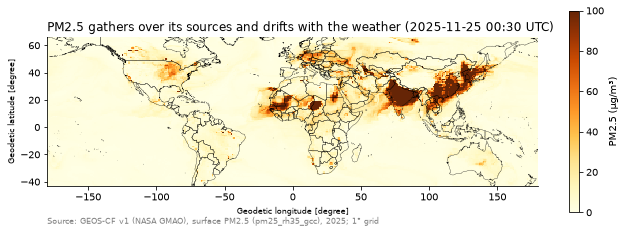

In [6]:
worst = daily[MUST].idxmax().date()
path = RAW / "screen" / f"world_{worst:%Y%m%d}.npy"
if not path.exists():
    np.save(path, world_grid(worst))
fig, ax = plt.subplots(figsize=(11, 5.2))
mesh = ax.pcolormesh(SCREEN_LONS, SCREEN_LATS, np.load(path), cmap="YlOrBr", vmin=0, vmax=100, shading="nearest")
countries.boundary.plot(ax=ax, color="k", linewidth=0.3)
ax.set_xlim(-180, 180); ax.set_ylim(SOUTH, NORTH); ax.set_aspect("equal")
ax.set_title(f"PM2.5 gathers over its sources and drifts with the weather ({worst:%Y-%m-%d} {SAMPLE_UTC:02d}:30 UTC)", loc="left")
fig.colorbar(mesh, ax=ax, shrink=0.7, label="PM2.5 (µg/m³)")
source_note(ax, CREDIT + "; 1° grid")
plt.show()

## 4. How often each city's air swings

From each city's 365 daily values:

- low band: days at or below the city's own 10th percentile; high band: at or above its 90th percentile
- a **swing** is one crossing from the low band to the high band, or back; days in between keep the last band
- ranked by swings; ties go to the city whose high band is more times its low band (p90 / p10)

The bands are each city's own, so a clean city and a dirty city are compared by how often they go back and forth, not by how dirty they get. The p10 and p90 columns show how far apart the bands are.

In [7]:
def swings(values, low, high):
    # Each crossing from the low band to the high band or back; days between the bands keep the last band.
    band, count, days = None, 0, []
    for i, v in enumerate(values):
        now = "low" if v <= low else "high" if v >= high else band
        if band is not None and now != band:
            count += 1
            days.append(i)
        band = now
    return count, days


def measure(series):
    low, high = np.quantile(series, LOW_Q), np.quantile(series, HIGH_Q)
    count, _ = swings(series, low, high)
    return {"swings": count, "p10": low, "median": np.median(series), "p90": high, "p90/p10": high / low}


ranked = (pd.concat([cities[["city", "country", "region", "population"]],
                     pd.DataFrame([measure(daily[c].values) for c in cities["city"]])], axis=1)
          .sort_values(["swings", "p90/p10"], ascending=False).reset_index(drop=True))
ranked.index += 1
print(f"swings per city: median {ranked['swings'].median():.0f}, max {ranked['swings'].max()}")
ranked.head(25).round(1)

swings per city: median 13, max 38


,city,country,region,population,swings,p10,median,p90,p90/p10
1,Pretoria,South Africa,Southern Africa,1338000,38,32.200001,58.299999,127.300003,4.0
2,Johannesburg,South Africa,Southern Africa,3435000,38,32.200001,58.299999,127.300003,4.0
3,New York,United States of America,Northern America,19040000,32,10.200000,27.400000,64.300003,6.3
4,Lisbon,Portugal,Southern Europe,2812000,32,4.900000,10.600000,24.400000,5.0
5,Sydney,Australia,Australia and New Zealand,4630000,32,3.000000,5.700000,12.300000,4.1
6,Port Louis,Mauritius,Eastern Africa,595491,31,1.800000,2.600000,4.200000,2.4
7,Auckland,New Zealand,Australia and New Zealand,1377200,30,1.300000,2.300000,4.600000,3.6
8,Montevideo,Uruguay,South America,1513000,29,1.800000,5.500000,16.600000,9.2
9,Algiers,Algeria,Northern Africa,3354000,29,6.900000,20.500000,61.099998,8.9
10,Cape Town,South Africa,Southern Africa,3215000,29,1.300000,2.900000,11.700000,8.9


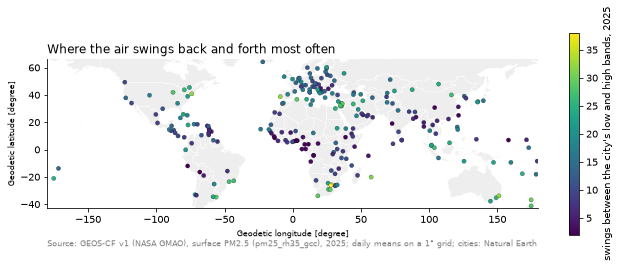

,count,median,max
region,,,
Southern Africa,9,27.0,38
Australia and New Zealand,5,28.0,32
Southern Europe,16,17.0,32
Northern America,12,20.5,32
Eastern Africa,20,9.5,31
Northern Africa,9,23.0,29
Western Asia,20,18.0,29
South America,16,13.0,29
South-Eastern Asia,14,17.0,27


In [8]:
fig, ax = plt.subplots(figsize=(11, 5.2))
countries.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.4)
pts = cities.merge(ranked[["city", "swings"]], on="city")
sc = ax.scatter(pts["lon"], pts["lat"], c=pts["swings"], cmap="viridis", s=18, edgecolor="k", linewidth=0.2)
fig.colorbar(sc, ax=ax, shrink=0.7, label=f"swings between the city's low and high bands, {YEAR}")
ax.set_xlim(-180, 180); ax.set_ylim(SOUTH, NORTH)
ax.set_title("Where the air swings back and forth most often", loc="left")
source_note(ax, CREDIT + "; daily means on a 1° grid; cities: Natural Earth")
plt.show()

by_region = (ranked.groupby("region")["swings"].agg(["count", "median", "max"])
             .sort_values("max", ascending=False))
by_region

## 5. The picks: Seoul and one city from each of three other regions

Seoul is in by choice. The other three are the highest-ranked cities, each from a UN subregion not already taken (Seoul's, Eastern Asia, is taken first).

In [9]:
seoul = ranked[ranked["city"] == MUST].iloc[0]
picked, regions = [seoul], {seoul["region"]}
for _, row in ranked.iterrows():
    if len(picked) == PICKS + 1:
        break
    if row["region"] not in regions:
        picked.append(row)
        regions.add(row["region"])
picks = pd.DataFrame(picked)
picks.insert(0, "rank", picks.index)
print(f"{MUST} ranks {seoul.name} of {len(ranked)} with {seoul['swings']} swings")
picks.round(1)

Seoul ranks 170 of 243 with 8 swings


,rank,city,country,region,population,swings,p10,median,p90,p90/p10
170,170,Seoul,South Korea,Eastern Asia,9796000,8,9.9,37.1,91.6,9.2
1,1,Pretoria,South Africa,Southern Africa,1338000,38,32.2,58.3,127.3,4.0
3,3,New York,United States of America,Northern America,19040000,32,10.2,27.4,64.3,6.3
4,4,Lisbon,Portugal,Southern Europe,2812000,32,4.9,10.6,24.4,5.0


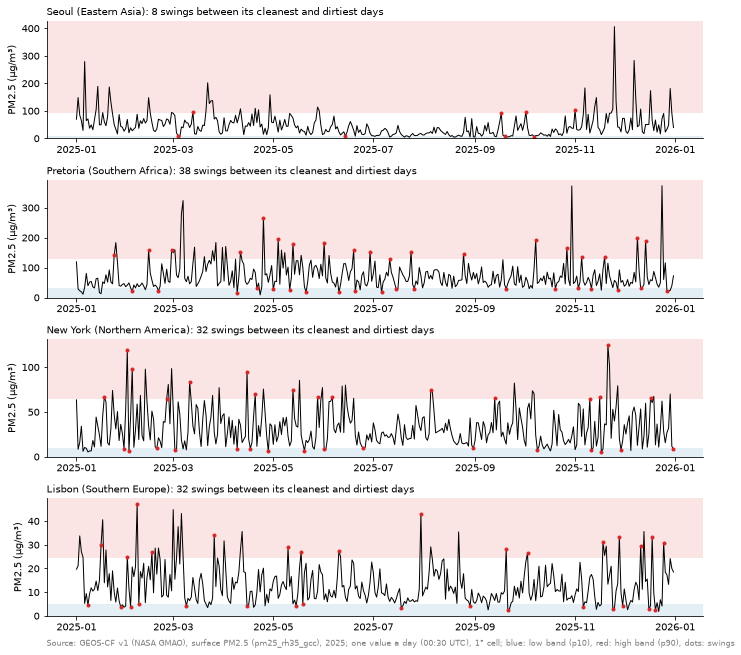

In [10]:
fig, axes = plt.subplots(len(picks), 1, figsize=(11, 2.3 * len(picks)))
for ax, c in zip(axes, picks["city"]):
    d = daily[c]
    low, high = np.quantile(d, LOW_Q), np.quantile(d, HIGH_Q)
    count, at = swings(d.values, low, high)
    ax.plot(d.index, d.values, color="k", lw=1)
    ax.axhspan(0, low, color="tab:blue", alpha=0.12, lw=0)
    ax.axhspan(high, d.max() * 1.05, color="tab:red", alpha=0.12, lw=0)
    ax.plot(d.index[at], d.values[at], "o", ms=3, color="tab:red")
    ax.set_ylim(0, d.max() * 1.05)
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.set_title(f"{c} ({picks.set_index('city').loc[c, 'region']}): {count} swings between its cleanest and dirtiest days",
                 loc="left", fontsize=10)
source_note(axes[-1], CREDIT + f"; one value a day ({SAMPLE_UTC:02d}:30 UTC), 1° cell; "
            "blue: low band (p10), red: high band (p90), dots: swings", y=-30)
fig.tight_layout()
plt.show()

## 6. Track data: the air around each city

[5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) · source: [GEOS-CF v1](https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1)

Each track plays one city's 2025, a day a sixteenth note. The globe holds still over the city (it cannot be turned or zoomed, user 2026-11-15) and draws the smog over a box around it, so only that box is downloaded:

- the city's 0.25° cell and 16 cells each way: 33 × 33 cells, ±4° (user, 2026-11-15)
- the same hour as the screening, 00:30 UTC, every day of 2025: one request per city per day, about 5 KB

The music reads the city's own cell at 0.25°, finer than the 1° screening cell, so its swings are counted again here with the same rule (section 4). Each swing is marked by where the air went: `smog` into the city's high band, `clear` into its low band.

Exported to `data/smog/tracks/`:

- `<city>_2025.csv`: `date`, `pm25_ugm3` (the city's cell, 0.1 µg/m³) and `swing` (`smog`, `clear` or empty)
- `<city>_2025_grid.csv`: `date` and the box's cells, `pm25_ugm3_r<row>_c<col>` (row 0 is the box's south edge, column 0 its west edge), rounded to whole µg/m³ for the map
- `tracks.json`: each track's sources, the city's place and the box

In [11]:
BOX = 16                                   # cells each way from the city's cell: ±4° at 0.25°
(RAW / "box").mkdir(exist_ok=True)
TRACKS = Path("../data/smog/tracks")
TRACKS.mkdir(parents=True, exist_ok=True)
track_cities = cities.set_index("city").loc[picks["city"]]


def box_day(args):
    city, day = args
    path = RAW / "box" / city / f"{day:%Y%m%d}.npy"
    if not path.exists():
        r, c = cell(track_cities.loc[city, "lat"], track_cities.loc[city, "lon"])
        t = hour_index(datetime.combine(day, datetime.min.time(), timezone.utc) + timedelta(hours=SAMPLE_UTC, minutes=30))
        sel = f"[{t}][0][{r - BOX}:{r + BOX}][{c - BOX}:{c + BOX}]"
        path.parent.mkdir(exist_ok=True)
        np.save(path, parse_dods(fetch(f"{OPENDAP}.dods?{VARIABLE}{sel}"), (1, 1, 2 * BOX + 1, 2 * BOX + 1))[0, 0])
    return np.load(path)


with ThreadPoolExecutor(PARALLEL) as pool:
    boxes = {city: np.stack(list(pool.map(box_day, [(city, d) for d in DAYS]))) for city in track_cities.index}
for city, box in boxes.items():
    print(f"{city}: {box.shape[0]} days × {box.shape[1]} × {box.shape[2]} cells, PM2.5 {box.min():.1f} to {box.max():.0f} µg/m³")

Seoul: 365 days × 33 × 33 cells, PM2.5 1.2 to 593 µg/m³
Pretoria: 365 days × 33 × 33 cells, PM2.5 0.5 to 993 µg/m³
New York: 365 days × 33 × 33 cells, PM2.5 1.0 to 905 µg/m³
Lisbon: 365 days × 33 × 33 cells, PM2.5 0.5 to 5789 µg/m³


In [12]:
def swing_marks(values):
    low, high = np.quantile(values, LOW_Q), np.quantile(values, HIGH_Q)
    count, at = swings(values, low, high)
    marks = np.full(len(values), "", dtype=object)
    for i in at:
        marks[i] = "smog" if values[i] >= high else "clear"
    return marks, count, low, high


rows, entries = [], []
for city, box in boxes.items():
    centre = np.round(box[:, BOX, BOX].astype(float), 1)
    marks, count, low, high = swing_marks(centre)
    slug = city.lower().replace(" ", "_")
    pd.DataFrame({"date": [f"{d:%Y-%m-%d}" for d in DAYS], "pm25_ugm3": centre, "swing": marks}).to_csv(
        TRACKS / f"{slug}_2025.csv", index=False)
    grid = pd.DataFrame(np.round(box.reshape(len(DAYS), -1)).astype(int),
                        columns=[f"pm25_ugm3_r{r:02d}_c{c:02d}" for r in range(2 * BOX + 1) for c in range(2 * BOX + 1)])
    grid.insert(0, "date", [f"{d:%Y-%m-%d}" for d in DAYS])
    grid.to_csv(TRACKS / f"{slug}_2025_grid.csv", index=False)
    r, c = cell(track_cities.loc[city, "lat"], track_cities.loc[city, "lon"])
    rows.append({"city": city, "swings (0.25°)": count, "swings (1°, section 4)": picks.set_index("city").loc[city, "swings"],
                 "smog": int((marks == "smog").sum()), "clear": int((marks == "clear").sum()),
                 "p10": low, "p90": high,
                 "track KB": (TRACKS / f"{slug}_2025.csv").stat().st_size / 1e3,
                 "grid KB": (TRACKS / f"{slug}_2025_grid.csv").stat().st_size / 1e3})
    entries.append({
        "file": f"{slug}_2025.csv",
        "title": city,
        "pages": [{"svsId": 5151, "svsUrl": "https://svs.gsfc.nasa.gov/5151/",
                   "message": "Though small particles typically remain in the atmosphere for only a few days, they can be "
                              "transported far away from source regions by large scale weather systems."}],
        "note": "Ours: the city picked by how often its PM2.5 swings between its own cleanest-10 % and dirtiest-10 % days "
                "in 2025 (Seoul by choice); one hour a day (00:30 UTC); each swing marked smog (into the high band) or "
                "clear (into the low band).",
        "sources": [{
            "source": "GEOS-CF v1 (NASA GMAO), aqc_tavg_1hr_g1440x721_v1, pm25_rh35_gcc",
            "sourceUrl": "https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/",
            "downloadUrl": f"{OPENDAP}.dods?{VARIABLE}[<hour>][0][{r - BOX}:{r + BOX}][{c - BOX}:{c + BOX}]",
            "version": "v1",
            "doi": "https://doi.org/10.1029/2020MS002413",
            "downloaded": "2026-11-15",
            "license": "NASA data, no restrictions on use",
            "credit": "Keller, C. A., et al. (2021). Description of the NASA GEOS composition forecast modeling system GEOS-CF v1.0. JAMES 13, e2020MS002413.",
            "substitute": "EIC 5151 links GEOS-CF v2, which starts on 2025-08-04 and holds no whole calendar year; v1 holds all of 2025 (user, 2026-11-15).",
        }],
        "visuals": [f"{slug}_2025_grid.csv"],
        "city": {"name": city, "country": track_cities.loc[city, "country"],
                 "lat": float(track_cities.loc[city, "lat"]), "lon": float(track_cities.loc[city, "lon"])},
        "grid": {"south": (r - BOX) * GRID_DEG - 90, "west": (c - BOX) * GRID_DEG - 180, "stepDeg": GRID_DEG,
                 "rows": 2 * BOX + 1, "cols": 2 * BOX + 1, "sampleUtc": f"{SAMPLE_UTC:02d}:30"},
        "units": {"pm25_ugm3": "µg/m³ (surface PM2.5 at 35 % relative humidity)",
                  "swing": "smog: the day the air crosses into the city's high band (p90); clear: into its low band (p10)"},
        "timeRange": [f"{DAYS[0]:%Y-%m-%d}", f"{DAYS[-1]:%Y-%m-%d}"],
    })
(TRACKS / "tracks.json").write_text(json.dumps(entries, indent=2, ensure_ascii=False) + "\n")
pd.DataFrame(rows).set_index("city").round(1)

,swings (0.25°),"swings (1°, section 4)",smog,clear,p10,p90,track KB,grid KB
city,,,,,,,,
Seoul,6,8,3,3,10.7,100.6,6.3,1180.0
Pretoria,20,38,10,10,25.3,135.3,6.4,1068.6
New York,30,32,15,15,13.7,55.5,6.4,1061.8
Lisbon,32,32,16,16,4.3,24.8,6.2,950.5


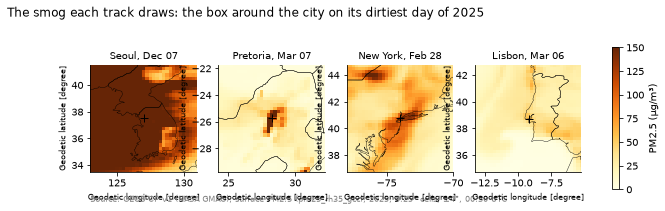

In [13]:
fig, axes = plt.subplots(1, len(boxes), figsize=(11, 3.2))
for ax, (city, box) in zip(axes, boxes.items()):
    day = int(np.argmax(box[:, BOX, BOX]))
    g = entries[list(boxes).index(city)]["grid"]
    lats = g["south"] + GRID_DEG * np.arange(g["rows"])
    lons = g["west"] + GRID_DEG * np.arange(g["cols"])
    mesh = ax.pcolormesh(lons, lats, box[day], cmap="YlOrBr", vmin=0, vmax=150, shading="nearest")
    countries.boundary.plot(ax=ax, color="k", linewidth=0.4)
    ax.plot(track_cities.loc[city, "lon"], track_cities.loc[city, "lat"], "k+", ms=8)
    ax.set_xlim(lons[0], lons[-1]); ax.set_ylim(lats[0], lats[-1]); ax.set_aspect("equal")
    ax.set_title(f"{city}, {DAYS[day]:%b %d}", fontsize=10)
fig.colorbar(mesh, ax=axes, shrink=0.8, label="PM2.5 (µg/m³)")
fig.suptitle("The smog each track draws: the box around the city on its dirtiest day of 2025", x=0.02, ha="left")
source_note(axes[0], CREDIT + f"; 0.25° cells, ±4°, {SAMPLE_UTC:02d}:30 UTC", y=-30)
plt.show()

## 7. Summary

| Item | Value |
| --- | --- |
| EIC page | [5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) |
| EIC message | PM2.5 harms health, pulses through the day, and is carried away from its sources by the weather within days |
| Our measure | Swings: crossings between a city's own cleanest-10 % and dirtiest-10 % days, in 2025 |
| Tracks | Seoul, Pretoria, New York, Lisbon (table below): each city's 2025, one value a day at 00:30 UTC, its own 0.25° cell for the music and a ±4° box of 0.25° cells for the map; 365 days a sixteenth note each, about 40 seconds |
| Swings the music plays | Counted again on the city's 0.25° cell (section 6); Pretoria's fall from 38 to 20, the others' stay close |

In [14]:
picks.set_index("city")[["country", "region", "swings", "p10", "median", "p90"]].round(1)

,country,region,swings,p10,median,p90
city,,,,,,
Seoul,South Korea,Eastern Asia,8,9.9,37.1,91.6
Pretoria,South Africa,Southern Africa,38,32.2,58.3,127.3
New York,United States of America,Northern America,32,10.2,27.4,64.3
Lisbon,Portugal,Southern Europe,32,4.9,10.6,24.4
